# Regression with ARMA Errors

The model $y_t=x_t^\top\beta+n_t$ with $\phi(B)n_t=\theta(B)\varepsilon_t$ separates the predictor-driven mean from serially dependent errors. OLS stays consistent under exogeneity but its independent-error standard errors are wrong, and the error model also improves forecasts.

This notebook checks the note's numbers ($y_t=1+2x_t+n_t$, $n_t=0.7n_{t-1}+\varepsilon_t$), simulates that model, compares OLS with a joint regression-with-AR-errors fit, and verifies the forecast contribution of the error term.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
import statsmodels.api as sm
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf

rng = np.random.default_rng(11)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

# Worked example: x_t = 3, n_t = 0.4, n_{t-1} = 0.5, rho = 0.7
mean = 1 + 2 * 3
print("regression mean   :", mean)
print("y_t               :", mean + 0.4)
print("AR contribution   :", 0.7 * 0.5)
print("innovation eps_t  :", round(0.4 - 0.7 * 0.5, 2))

regression mean   : 7
y_t               : 7.4
AR contribution   : 0.35
innovation eps_t  : 0.05


This confirms $y_t=7.4$, a predictable error component $0.7(0.5)=0.35$, and a new innovation $\varepsilon_t=0.05$.

## Simulate the model

Use $\beta_0=1$, $\beta_1=2$, $\rho=0.7$, $\sigma_\varepsilon=1$, and a persistent predictor (so the dependence in the errors matters for inference).

theoretical Var(n_t) = 1/(1-rho^2) = 1.961   sample: 2.254


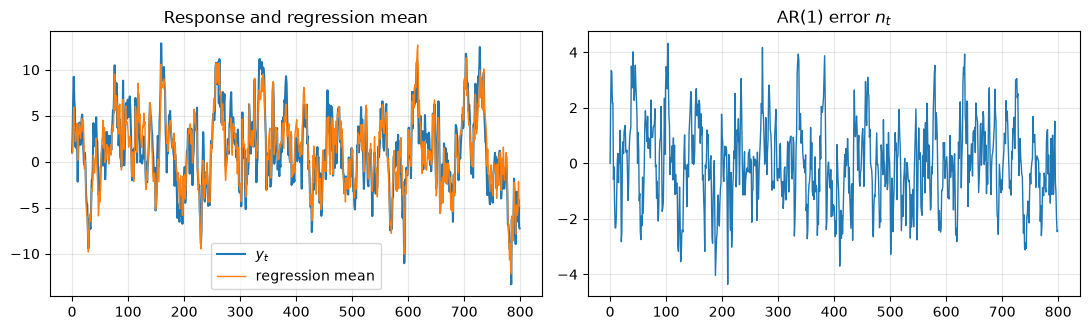

In [2]:
n, rho, b0, b1 = 800, 0.7, 1.0, 2.0
x = np.zeros(n)
for t in range(1, n):
    x[t] = 0.9 * x[t - 1] + rng.normal()
eps = rng.normal(size=n)
err = np.zeros(n)
for t in range(1, n):
    err[t] = rho * err[t - 1] + eps[t]
y = b0 + b1 * x + err

print("theoretical Var(n_t) = 1/(1-rho^2) =", round(1 / (1 - rho**2), 3), "  sample:", err.var().round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(y, label="$y_t$"); ax[0].plot(b0 + b1 * x, label="regression mean", lw=1)
ax[0].legend(); ax[0].set_title("Response and regression mean")
ax[1].plot(err, lw=1); ax[1].set_title("AR(1) error $n_t$")
plt.tight_layout(); plt.show()

The response wanders around the regression mean in persistent excursions: the error is not white. The sample error variance is of the same order as the theoretical $\sigma_\varepsilon^2/(1-\rho^2)\approx1.96$ (persistent errors make the sample variance noisy).

## OLS versus regression with AR(1) errors

Fit OLS (with naive and HAC standard errors) and a joint model with `SARIMAX(y, exog=x, order=(1,0,0), trend='c')`. Then check the residual ACF of each.

true            : const=1.000  beta=2.000  rho=0.700
OLS             : const=0.987  beta=2.022  se(beta) naive=0.0269  HAC=0.0452
Reg+AR(1) errors: const=0.977  beta=2.036  rho=0.745  se(beta)=0.0368


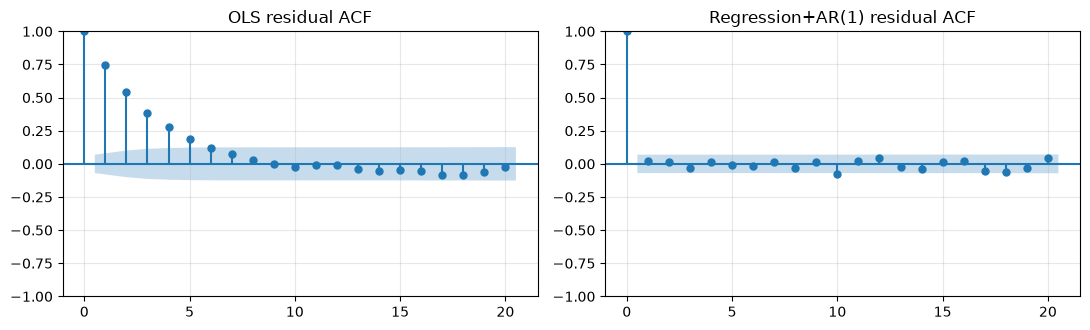

In [3]:
X = sm.add_constant(x)
ols = sm.OLS(y, X).fit()
hac = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
sar = SARIMAX(y, exog=x, order=(1, 0, 0), trend="c").fit(disp=False)

print("true            : const=1.000  beta=2.000  rho=0.700")
print(f"OLS             : const={ols.params[0]:.3f}  beta={ols.params[1]:.3f}  se(beta) naive={ols.bse[1]:.4f}  HAC={hac.bse[1]:.4f}")
# statsmodels puts the constant in the AR equation, so the regression intercept is c / (1 - rho)
c, beta, rho_hat = sar.params[0], sar.params[1], sar.params[2]
print(f"Reg+AR(1) errors: const={c/(1-rho_hat):.3f}  beta={beta:.3f}  rho={rho_hat:.3f}  se(beta)={sar.bse[1]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
plot_acf(ols.resid, lags=20, ax=ax[0], title="OLS residual ACF")
plot_acf(sar.resid[1:], lags=20, ax=ax[1], title="Regression+AR(1) residual ACF")
plt.tight_layout(); plt.show()

All three estimators recover $\beta\approx2$ (OLS is consistent), but the naive OLS standard error understates the uncertainty relative to the HAC and joint-model values. OLS residuals show a strong autocorrelation pattern, while the joint model's residuals are close to white, and its estimated $\rho$ is near the true $0.7$. The intercept is reported as the regression intercept $c/(1-\hat\rho)$, because statsmodels places the constant in the AR equation.

## Forecasting benefit of the error model

The one-step forecast is $\hat y_{t+1|t}=x_{t+1}^\top\hat\beta+\hat\rho\,\hat n_t$. A predictor-only (OLS) forecast ignores the latest error. Compare one-step errors on a hold-out sample, given the future predictor values.

hold-out RMSE  OLS mean only : 1.336
hold-out RMSE  regression+AR : 0.887   (innovation sd = 1)


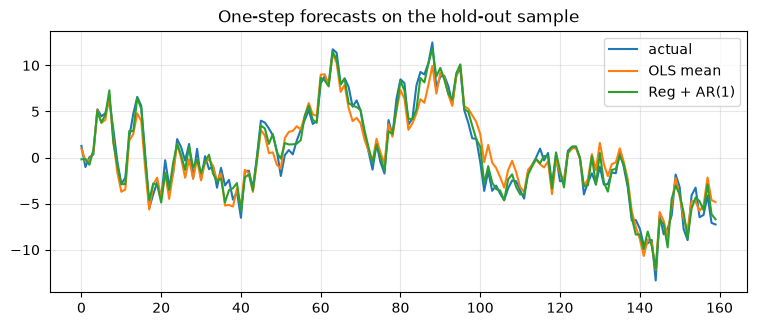

In [4]:
split = 640
fit_ols = sm.OLS(y[:split], sm.add_constant(x[:split])).fit()
fit_sar = SARIMAX(y[:split], exog=x[:split], order=(1, 0, 0), trend="c").fit(disp=False)

# one-step-ahead forecasts through the hold-out, using the true past observations
res = fit_sar.append(y[split:], exog=x[split:])
pred_sar = res.predict(start=split, end=n - 1)
pred_ols = fit_ols.params[0] + fit_ols.params[1] * x[split:]

rmse = lambda p: np.sqrt(np.mean((y[split:] - p) ** 2))
print(f"hold-out RMSE  OLS mean only : {rmse(pred_ols):.3f}")
print(f"hold-out RMSE  regression+AR : {rmse(pred_sar):.3f}   (innovation sd = 1)")

plt.figure(figsize=(9, 3.4))
plt.plot(y[split:], label="actual"); plt.plot(pred_ols, label="OLS mean"); plt.plot(pred_sar, label="Reg + AR(1)")
plt.legend(); plt.title("One-step forecasts on the hold-out sample"); plt.show()

The regression-with-AR-errors forecast has RMSE close to the innovation standard deviation $1$, while the mean-only forecast is noticeably worse because it throws away the predictable part $\rho n_t$ of the next error. Modelling the dependence matters for both inference and prediction.